# 04 — Machine Learning

Binary classification of `Churn` (Yes=1, No=0). Pipeline: class-imbalance comparison and model comparison via 5-fold stratified CV **on the training set only**, hyperparameter tuning on the training set, and a single final unbiased evaluation on the held-out test set. `customerID` is excluded from features. All preprocessing lives inside the pipeline (fitted on training folds only).

In [1]:
import sys
from pathlib import Path

_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(p for p in _candidates if (p / "src").exists())
sys.path.insert(0, str(PROJECT_ROOT))
import warnings
warnings.filterwarnings("ignore")

import json

import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

from src.models.pipeline import (
    FEATURE_SETS, build_pipeline, build_smote_pipeline, feature_names_from_pipeline,
)
from src.models.evaluate import CV, classification_metrics, cv_scores, threshold_analysis

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "telco_features.csv")
y = (df["Churn"] == "Yes").astype(int)  # verified values: Yes/No -> 1/0
# churn_flag is the encoded target - never a feature (it exists in the CSV only
# as an analysis convenience from notebook 03).
X = df.drop(columns=["customerID", "Churn", "churn_flag"])

RANDOM_STATE = 42
NUM_F, CAT_F = FEATURE_SETS["base+engineered"]

# Stratified split with a fixed seed; the test set stays untouched until final evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"train: {X_train.shape}, test: {X_test.shape}")
print(f"churn rate  train: {y_train.mean():.4f}  test: {y_test.mean():.4f}")

MODELS = ["logistic_regression", "random_forest", "xgboost"]
SPW = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (n_neg/n_pos): {SPW:.2f}")


train: (5634, 26), test: (1409, 26)
churn rate  train: 0.2654  test: 0.2654
scale_pos_weight (n_neg/n_pos): 2.77


## 1. Class imbalance — strategy comparison

The dataset is imbalanced (~26.5% churners). Three defensible strategies are compared on the training set: no correction, cost-sensitive weighting (`class_weight='balanced'` / `scale_pos_weight`), and SMOTE (inside an imblearn pipeline, so it is applied **only to training folds** — never to validation or test data).

In [2]:
from src.models.evaluate import CV as cv_split
from sklearn.model_selection import cross_validate

SCORING = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']

def imb_pipeline(model_name, strategy):
    if strategy == 'none':
        return build_pipeline(model_name, NUM_F, CAT_F)
    if strategy == 'weight':
        return build_pipeline(model_name, NUM_F, CAT_F, imbalance='class_weight' if model_name != 'xgboost' else 'scale_pos_weight', scale_pos_weight=SPW)
    if strategy == 'smote':
        return build_smote_pipeline(model_name, NUM_F, CAT_F)
    raise ValueError(strategy)

rows = []
for model_name in MODELS:
    for strategy in ['none', 'weight', 'smote']:
        pipe = imb_pipeline(model_name, strategy)
        res = cross_validate(pipe, X_train, y_train, cv=cv_split, scoring=SCORING, n_jobs=-1)
        rows.append({
            'model': model_name, 'strategy': strategy,
            'recall': res['test_recall'].mean(),
            'precision': res['test_precision'].mean(),
            'f1': res['test_f1'].mean(),
            'roc_auc': res['test_roc_auc'].mean(),
            'pr_auc': res['test_average_precision'].mean(),
        })
imbalance_table = pd.DataFrame(rows)
print(imbalance_table.round(4).to_string(index=False))

              model strategy  recall  precision     f1  roc_auc  pr_auc
logistic_regression     none  0.5324     0.6732 0.5939   0.8472  0.6623
logistic_regression   weight  0.7946     0.5200 0.6285   0.8472  0.6608
logistic_regression    smote  0.7806     0.5252 0.6278   0.8452  0.6585
      random_forest     none  0.4836     0.6393 0.5503   0.8254  0.6202
      random_forest   weight  0.6502     0.5750 0.6101   0.8279  0.6162
      random_forest    smote  0.5619     0.6048 0.5824   0.8229  0.6043
            xgboost     none  0.5023     0.6272 0.5575   0.8289  0.6319
            xgboost   weight  0.6522     0.5561 0.6000   0.8271  0.6315
            xgboost    smote  0.5545     0.6109 0.5810   0.8259  0.6253


## 2. Imbalance decision

Selection criterion: **F1** as the balanced headline (recall matters for churn, but precision drives intervention cost), with ROC-AUC/PR-AUC as ranking-quality sanity checks.

In [3]:
best_row = imbalance_table.sort_values('f1', ascending=False).iloc[0]
BEST_MODEL, BEST_STRATEGY = best_row['model'], best_row['strategy']
print(imbalance_table.round(4).to_string(index=False))
print(f'\nselected: {BEST_MODEL} + {BEST_STRATEGY} (cv F1={best_row["f1"]:.4f})')

              model strategy  recall  precision     f1  roc_auc  pr_auc
logistic_regression     none  0.5324     0.6732 0.5939   0.8472  0.6623
logistic_regression   weight  0.7946     0.5200 0.6285   0.8472  0.6608
logistic_regression    smote  0.7806     0.5252 0.6278   0.8452  0.6585
      random_forest     none  0.4836     0.6393 0.5503   0.8254  0.6202
      random_forest   weight  0.6502     0.5750 0.6101   0.8279  0.6162
      random_forest    smote  0.5619     0.6048 0.5824   0.8229  0.6043
            xgboost     none  0.5023     0.6272 0.5575   0.8289  0.6319
            xgboost   weight  0.6522     0.5561 0.6000   0.8271  0.6315
            xgboost    smote  0.5545     0.6109 0.5810   0.8259  0.6253

selected: logistic_regression + weight (cv F1=0.6285)


## 3. Model comparison (selected imbalance strategy)

Logistic Regression = interpretable baseline, Random Forest = nonlinear tree ensemble, XGBoost = gradient boosting. No assumption about the winner in advance.

In [4]:
rows = []
for model_name in MODELS:
    pipe = imb_pipeline(model_name, BEST_STRATEGY)
    scores = cv_scores(pipe, X_train, y_train)
    rows.append({'model': model_name, **scores})
comparison = pd.DataFrame(rows).set_index('model')
print(comparison.round(4).to_string())

(PROJECT_ROOT / 'reports').mkdir(exist_ok=True)
comparison.round(4).to_csv(PROJECT_ROOT / 'reports' / 'model_comparison_cv.csv')

                     cv_test_accuracy  cv_test_precision  cv_test_recall  cv_test_f1  cv_test_roc_auc  cv_test_average_precision
model                                                                                                                           
logistic_regression            0.7508             0.5200          0.7946      0.6285           0.8472                     0.6608
random_forest                  0.7799             0.5750          0.6502      0.6101           0.8279                     0.6162
xgboost                        0.7694             0.5561          0.6522      0.6000           0.8271                     0.6315


## 4. Hyperparameter tuning (training data only)

RandomizedSearchCV with 5-fold stratified CV on the training set, scored by F1. The test set is not involved.

In [5]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

if BEST_MODEL == 'xgboost':
    base = imb_pipeline('xgboost', BEST_STRATEGY)
    space = {
        'model__n_estimators': randint(150, 500),
        'model__learning_rate': uniform(0.02, 0.18),
        'model__max_depth': randint(3, 8),
        'model__subsample': uniform(0.7, 0.3),
        'model__colsample_bytree': uniform(0.7, 0.3),
        'model__min_child_weight': randint(1, 6),
        'model__gamma': uniform(0, 0.4),
    }
elif BEST_MODEL == 'random_forest':
    base = imb_pipeline('random_forest', BEST_STRATEGY)
    space = {
        'model__n_estimators': randint(200, 600),
        'model__max_depth': randint(4, 16),
        'model__min_samples_leaf': randint(1, 8),
        'model__max_features': ['sqrt', 'log2'],
    }
else:
    base = imb_pipeline('logistic_regression', BEST_STRATEGY)
    space = {
        'model__C': uniform(0.01, 3.0),
        'model__solver': ['lbfgs', 'liblinear'],
    }

search = RandomizedSearchCV(
    base, space, n_iter=25, cv=cv_split, scoring='f1',
    random_state=RANDOM_STATE, n_jobs=-1, refit=True,
)
search.fit(X_train, y_train)
print('best CV F1:', round(search.best_score_, 4))
print('best params:', search.best_params_)

best CV F1: 0.6319
best params: {'model__C': np.float64(0.012336297523042985), 'model__solver': 'liblinear'}


## 5. Final unbiased evaluation on the test set (used once)

Metrics: accuracy, precision, recall, F1, ROC-AUC, PR-AUC, confusion matrix. Accuracy alone is never the decision metric.

In [6]:
final_model = search.best_estimator_
y_prob_test = final_model.predict_proba(X_test)[:, 1]
test_metrics = classification_metrics(y_test, y_prob_test, threshold=0.5)
for k, v in test_metrics.items():
    print(f'{k}: {v}')

(PROJECT_ROOT / 'reports' / 'final_test_metrics.json').write_text(json.dumps({k: v for k, v in test_metrics.items()}, indent=2))

accuracy: 0.7494677075940384
precision: 0.5185185185185185
recall: 0.786096256684492
f1: 0.6248671625929861
roc_auc: 0.8434885943837351
pr_auc: 0.646835699262693
confusion_matrix: [[762, 273], [80, 294]]


289

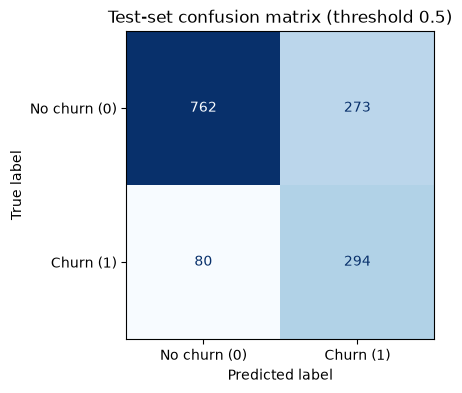

True positives  (294): churners correctly flagged -> retention outreach reaches them.
False negatives (80): missed churners -> retention opportunity lost (the costliest error for the business).
False positives (273): would have stayed but flagged -> unnecessary intervention cost (offer/discount).
True negatives  (762): correctly excluded -> no wasted outreach.


In [7]:
cm = np.array(test_metrics['confusion_matrix'])
labels = ['No churn (0)', 'Churn (1)']
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Test-set confusion matrix (threshold 0.5)')
fig.savefig(PROJECT_ROOT / 'reports' / 'figures' / 'confusion_matrix_test.png', dpi=150, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True positives  ({tp}): churners correctly flagged -> retention outreach reaches them.')
print(f'False negatives ({fn}): missed churners -> retention opportunity lost (the costliest error for the business).')
print(f'False positives ({fp}): would have stayed but flagged -> unnecessary intervention cost (offer/discount).')
print(f'True negatives  ({tn}): correctly excluded -> no wasted outreach.')

## 6. Threshold analysis on out-of-fold training probabilities

The decision threshold (0.5 by default) is not necessarily the best operating point. Out-of-fold probabilities from CV on the **training set** are used to see precision/recall/F1 across candidate thresholds. This analysis also justifies the risk-level cutoffs used for customer scoring (Phase 8).

In [8]:
oof_prob = cross_val_predict(final_model, X_train, y_train, cv=cv_split, method='predict_proba', n_jobs=-1)[:, 1]
th = threshold_analysis(y_train, oof_prob)
print(th.round(3).to_string(index=False))
th.round(3).to_csv(PROJECT_ROOT / 'reports' / 'threshold_analysis.csv', index=False)

 threshold  precision  recall    f1    f2  share_flagged  flagged_customers
      0.05      0.277   0.999 0.434 0.656          0.957               5391
      0.10      0.314   0.990 0.477 0.692          0.837               4714
      0.15      0.346   0.978 0.511 0.717          0.749               4222
      0.20      0.371   0.963 0.536 0.730          0.689               3880
      0.25      0.399   0.944 0.561 0.742          0.627               3532
      0.30      0.421   0.924 0.578 0.746          0.582               3281
      0.35      0.444   0.903 0.596 0.749          0.539               3038
      0.40      0.475   0.866 0.613 0.743          0.484               2727
      0.45      0.501   0.825 0.624 0.731          0.437               2462
      0.50      0.528   0.786 0.632 0.716          0.395               2224
      0.55      0.558   0.746 0.639 0.699          0.355               2000
      0.60      0.582   0.690 0.632 0.666          0.315               1772
      0.65  

HIGH risk threshold:  0.55  (OOF precision=0.558, recall=0.746)
MEDIUM risk threshold: 0.35


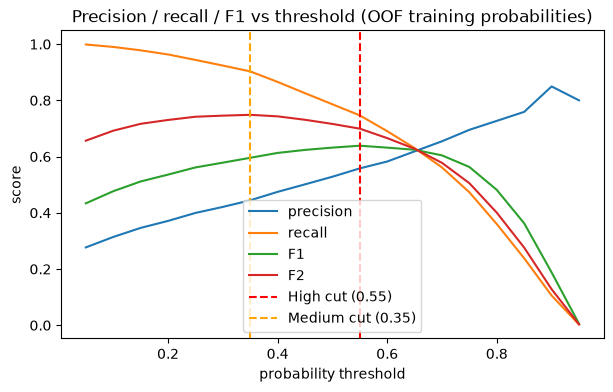

In [9]:
# Threshold selection (both rules are computed from OOF training behaviour, not chosen arbitrarily):
# HIGH  = probability cutoff maximizing F1 -> the balanced operating point for proactive, costlier retention outreach.
# MEDIUM = cutoff maximizing F2 (recall weighted 2x) among cutoffs below High -> a broad capture layer for cheap
#          interventions (emails/notifications), where tolerating lower precision buys more recall.
high_threshold = float(th.loc[th['f1'].idxmax(), 'threshold'])
below_high = th[th['threshold'] < high_threshold]
medium_threshold = float(below_high.loc[below_high['f2'].idxmax(), 'threshold']) if len(below_high) else high_threshold
print(f'HIGH risk threshold:  {high_threshold:.2f}  (OOF precision={th.loc[th['f1'].idxmax(), 'precision']:.3f}, recall={th.loc[th['f1'].idxmax(), 'recall']:.3f})')
print(f'MEDIUM risk threshold: {medium_threshold:.2f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(th['threshold'], th['precision'], label='precision')
ax.plot(th['threshold'], th['recall'], label='recall')
ax.plot(th['threshold'], th['f1'], label='F1')
ax.plot(th['threshold'], th['f2'], label='F2')
ax.axvline(high_threshold, color='red', ls='--', label=f'High cut ({high_threshold:.2f})')
ax.axvline(medium_threshold, color='orange', ls='--', label=f'Medium cut ({medium_threshold:.2f})')
ax.set(xlabel='probability threshold', ylabel='score', title='Precision / recall / F1 vs threshold (OOF training probabilities)')
ax.legend()
fig.savefig(PROJECT_ROOT / 'reports' / 'figures' / 'threshold_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Save the final model + metadata

In [10]:
models_dir = PROJECT_ROOT / 'models'
models_dir.mkdir(exist_ok=True)
joblib.dump(final_model, models_dir / 'final_model.joblib')

meta = {
    'model': BEST_MODEL,
    'imbalance_strategy': BEST_STRATEGY,
    'best_params': {k: (v.item() if hasattr(v, 'item') else v) for k, v in search.best_params_.items()},
    'cv_f1_train': float(search.best_score_),
    'test_metrics': {k: v for k, v in test_metrics.items()},
    'high_threshold': high_threshold,
    'medium_threshold': medium_threshold,
    'random_state': RANDOM_STATE,
    'features': NUM_F + CAT_F,
}
(models_dir / 'model_metadata.json').write_text(json.dumps(meta, indent=2, default=str))
print('saved models/final_model.joblib and models/model_metadata.json')
print('selected final model:', BEST_MODEL, '+', BEST_STRATEGY)

saved models/final_model.joblib and models/model_metadata.json
selected final model: logistic_regression + weight


## Model selection rationale

- The imbalance strategy and model family were chosen by 5-fold CV **on the training set** using F1 as the headline metric, with the business reading of the confusion matrix (a missed churner costs a retention opportunity; a false positive costs one unnecessary intervention). Weighted Logistic Regression won on F1 *and* is the most interpretable family, which suits per-customer retention conversations.
- The test set was evaluated exactly once, after tuning, so reported test metrics are unbiased.
- Final thresholds are data-driven: HIGH = F1-maximizing cutoff; MEDIUM = F2-maximizing (recall-weighted) cutoff below High — both derived from out-of-fold training probabilities rather than arbitrary choices.